# Análise Exploratória de Dados (EDA) - Video Game Sales
Nesta etapa inicial, nosso objetivo é compreender a estrutura do dataset, identificar a presença de valores ausentes (nulos) e analisar a distribuição estatística das vendas. Essa compreensão é vital para a etapa de Preparação de Dados (Data Preparation) do CRISP-DM, pois algoritmos de agrupamento (Clustering), como o K-Means, são altamente sensíveis a *outliers* e escalas desbalanceadas.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
sns.set_theme(style="whitegrid")

df = pd.read_csv('vgsales.csv')



## 1. Inspeção Inicial: O Topo do Mercado
Ao visualizar os primeiros registros, já notamos o domínio histórico de uma única publicadora no topo absoluto do mercado físico e digital clássico.

In [17]:
display(df.head())


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


**Conclusões do Cabeçalho:**
* A Nintendo é a publicadora (*Publisher*) de todos os 5 jogos mais vendidos da história deste dataset.
* O jogo *Wii Sports* é um fenômeno isolado, com incríveis 82.74 milhões de cópias globais, seguido por *Super Mario Bros.* com 40.24 milhões.
* Apenas analisando essas 5 linhas, já percebemos que o peso numérico das vendas na América do Norte (`NA_Sales`) costuma ser o componente majoritário da venda global (`Global_Sales`).

## 2. Estrutura e Valores Ausentes
Antes de qualquer modelagem matemática, precisamos garantir a integridade dos dados.

In [18]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


None

**Conclusões da Estrutura:**
* O dataset possui um total de 16.598 registros.
* Existem valores nulos em duas colunas específicas:
    * `Year` (Ano): Possui 16.327 registros não nulos, o que significa que faltam **271** datas de lançamento.
    * `Publisher` (Editora): Possui 16.540 registros não nulos, faltando **58** informações.
* Como o número de valores ausentes representa menos de 2% do total da nossa base, a exclusão dessas linhas (dropna) nas etapas futuras será uma abordagem segura que não comprometerá a análise geral.
* Os tipos de dados estão corretos: vendas formatadas como números de ponto flutuante (`float64`) e categorias como texto (`object`).

## 3. Estatísticas Descritivas e a Assimetria da Indústria
A regra de ouro do agrupamento: conhecer a distribuição dos dados contínuos.

In [19]:
display(df.describe())


,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


**Conclusões Descritivas (O Ponto Crítico para o Clustering):**
A tabela descritiva confirma nossa hipótese principal de negócio: a indústria de jogos é movida pela lógica de "Blockbusters" (pouquíssimos sucessos gigantescos e muitos jogos com vendas marginais). 

* **Média vs. Mediana:** A venda global média (`mean`) é de 0.53 milhões de cópias. No entanto, a mediana (`50%`) é de apenas 0.17 milhões. Isso significa que metade de todos os jogos lançados na história não chegam a vender nem 200 mil cópias.
* **O Efeito Outlier:** O desvio padrão de 1.55 frente a uma média de 0.53 já indica forte distorção. Mas o mais alarmante é o valor máximo (`max`): enquanto 75% dos jogos vendem até 0.47 milhões, o maior sucesso vendeu 82.74 milhões!
* **Decisão Metodológica:** Se aplicarmos o algoritmo K-Means diretamente nessas colunas sem tratamento prévio, o *Wii Sports* e o *Super Mario Bros.* "puxarão" os centroides para si, destruindo a formação dos clusters menores. Fica evidente a necessidade de **padronizar/normalizar** (ex: *StandardScaler* ou transformação Logarítmica) essas variáveis na fase de *Data Preparation* para mitigar o peso desses pontos fora da curva. Além disso, o ano de publicação dos jogos varia de 1980 a 2020, fornecendo um excelente intervalo para nossas análises temporais.

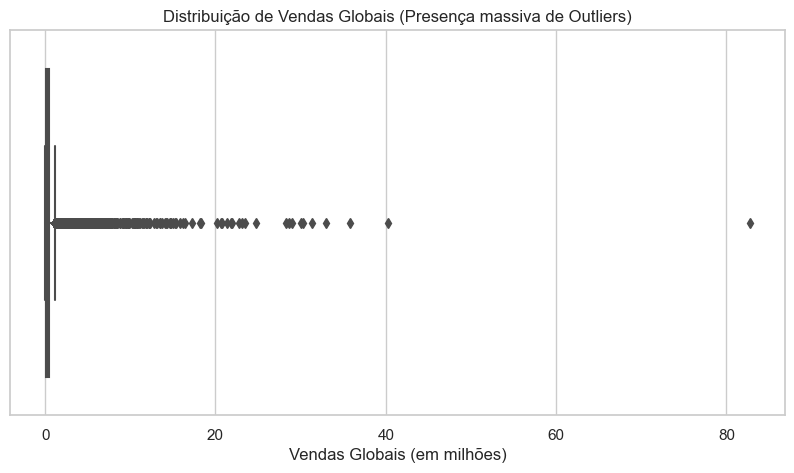

Linhas antes da limpeza: 16598
Linhas após a limpeza: 16291


In [20]:
# 1. Removendo as linhas com valores nulos identificadas no df.info()
df_clean = df.dropna().copy()

# 2. Convertendo a coluna Year para inteiro 
df_clean['Year'] = df_clean['Year'].astype(int)

# 3. Plotando a distorção das vendas globais para provar visualmente a análise do describe()
plt.figure(figsize=(10, 5))
sns.boxplot(x=df_clean['Global_Sales'])
plt.title('Distribuição de Vendas Globais (Presença massiva de Outliers)')
plt.xlabel('Vendas Globais (em milhões)')
plt.show()

print(f"Linhas antes da limpeza: {df.shape[0]}")
print(f"Linhas após a limpeza: {df_clean.shape[0]}")

### Conclusão Visual dos Outliers
O Boxplot evidencia uma assimetria extrema nas vendas globais. A vasta maioria dos jogos concentra-se na faixa inferior a 1 milhão de cópias, representados pela linha espessa no limite esquerdo do gráfico. Os pontos pretos espalhados à direita representam os "Blockbusters" da indústria. 

Para a etapa de clusterização, essa visualização dita uma regra clara: **precisaremos aplicar uma transformação logarítmica ou normalização robusta** nas variáveis de vendas numéricas. Caso contrário, algoritmos baseados em distância euclidiana (como o K-Means) criarão clusters enviesados, isolando os poucos megassucessos e aglomerando todos os outros milhares de jogos em um único grupo indistinguível.

## 4. Analisando o Eixo Categórico: Editoras e Gêneros
Nosso segundo passo na EDA é entender a fragmentação do mercado. Quantas empresas diferentes estão competindo e quais são os gêneros mais produzidos?

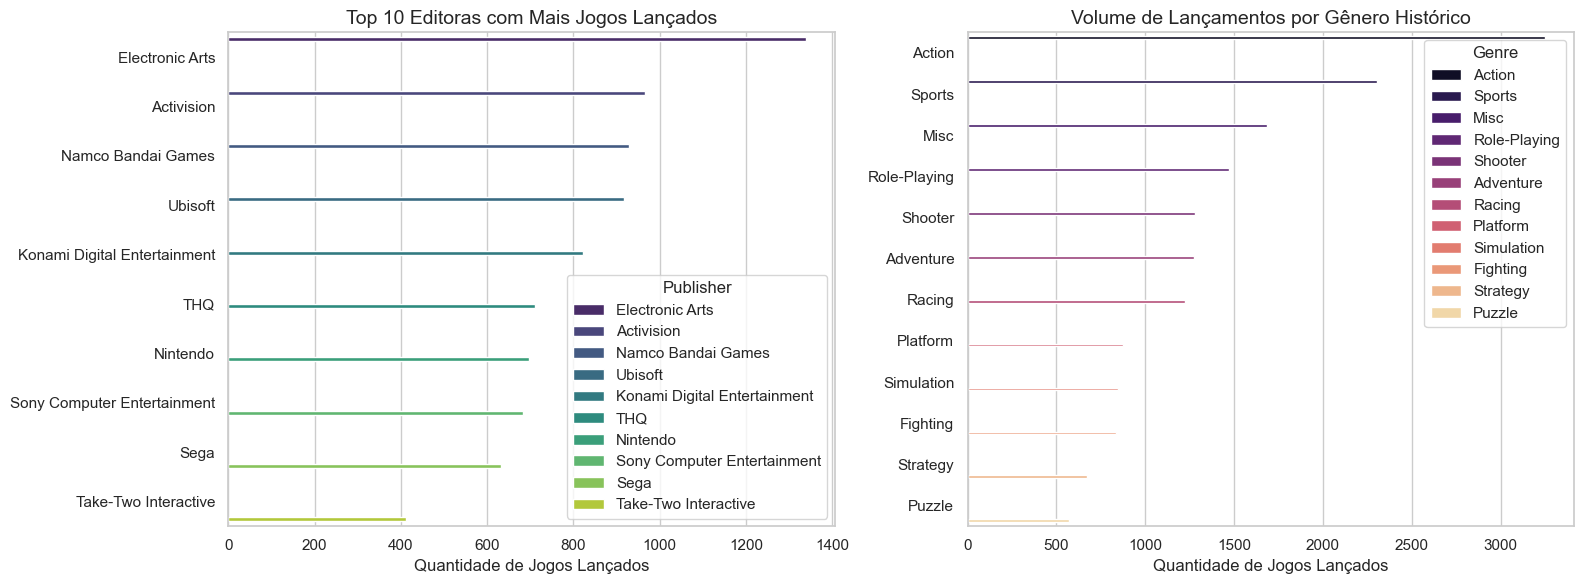

Total de Editoras Únicas na base: 576


In [21]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Top 10 Editoras (Publishers)
top_publishers = df_clean['Publisher'].value_counts().head(10)
sns.barplot(x=top_publishers.values, y=top_publishers.index, ax=axes[0], hue=top_publishers.index, palette='viridis')
axes[0].set_title('Top 10 Editoras com Mais Jogos Lançados', fontsize=14)
axes[0].set_xlabel('Quantidade de Jogos Lançados')
axes[0].set_ylabel('')

# Gráfico 2: Distribuição por Gênero
genre_counts = df_clean['Genre'].value_counts()
sns.barplot(x=genre_counts.values, y=genre_counts.index, ax=axes[1], hue=genre_counts.index, palette='magma')
axes[1].set_title('Volume de Lançamentos por Gênero Histórico', fontsize=14)
axes[1].set_xlabel('Quantidade de Jogos Lançados')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

total_publishers = df_clean['Publisher'].nunique()
print(f"Total de Editoras Únicas na base: {total_publishers}")

## 5. A Evolução Temporal (O Eixo dos Anos)
Como um dos nossos objetivos específicos é entender a transformação da indústria ao longo do tempo, precisamos visualizar o volume de lançamentos por ano. Isso nos ajudará a definir se vale a pena agrupar os jogos por "Eras" (ex: Anos 90 vs. Anos 2010).

c:\Users\Felipe\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Felipe\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


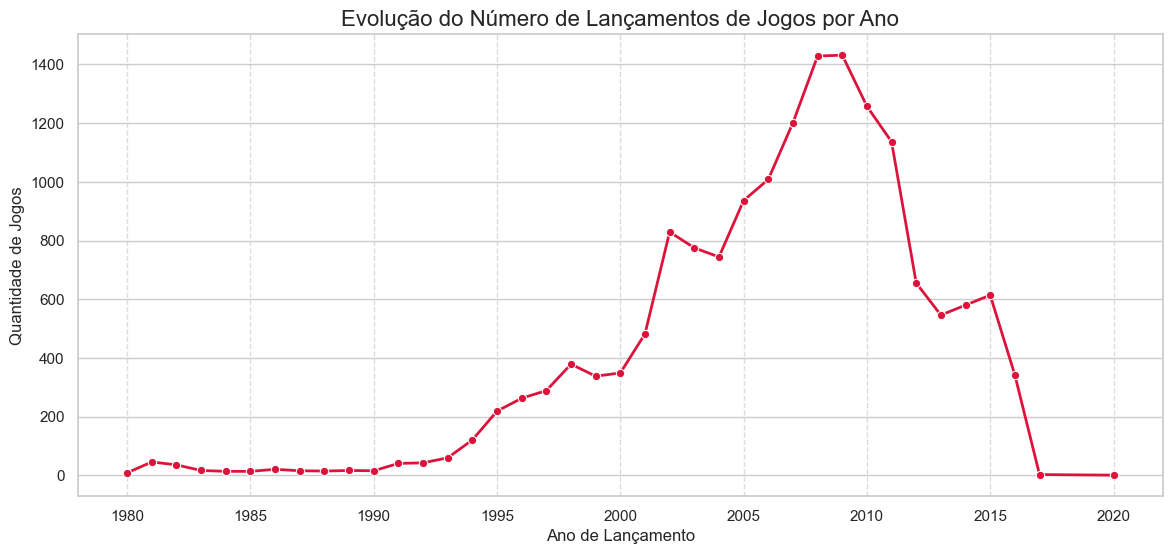

In [22]:
plt.figure(figsize=(14, 6))

releases_per_year = df_clean['Year'].value_counts().sort_index()

sns.lineplot(x=releases_per_year.index, y=releases_per_year.values, marker='o', color='crimson', linewidth=2)

plt.title('Evolução do Número de Lançamentos de Jogos por Ano', fontsize=16)
plt.xlabel('Ano de Lançamento', fontsize=12)
plt.ylabel('Quantidade de Jogos', fontsize=12)

plt.xticks(range(df_clean['Year'].min(), df_clean['Year'].max() + 1, 5))
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

### Conclusões do Perfil Categórico e Temporal
* **Estratégia de Publicação:** Há uma clara distinção no mercado. Empresas como Electronic Arts e Activision dominam em volume absoluto de lançamentos. Curiosamente, a Nintendo, dona dos maiores sucessos de vendas isolados, publica menos jogos, indicando uma estratégia focada em qualidade/megassucessos em vez de volume.
* **Alta Cardinalidade:** O dataset possui 576 editoras diferentes. Para algoritmos baseados em distância (K-Means/DBSCAN), isso causa a "maldição da dimensionalidade". Precisaremos agrupar as editoras menores em uma categoria "Outras" na fase de preparação.
* **Limitação da Base de Dados (O viés físico):** A curva temporal mostra um pico histórico entre 2007 e 2010 (a era de ouro dos jogos casuais e do Nintendo Wii) e uma queda drástica após 2015. Essa queda reflete a transição da indústria para a distribuição **digital**, que é sub-representada na metodologia de coleta do VGChartz. Portanto, nossos clusters refletirão majoritariamente o comportamento do **mercado de mídia física**.

---
# Fase 3: Preparação dos Dados (Data Preparation)
Nesta etapa, vamos transformar os dados brutos para que os algoritmos de agrupamento consigam interpretá-los matematicamente. Nossas duas missões aqui são:
1. Reduzir a cardinalidade das Editoras (Publishers).
2. Aplicar uma transformação (Logarítmica) nas vendas para suavizar a distorção dos *Outliers* que vimos no Boxplot.

Nova distribuição de Editoras:


Publisher_Grouped
Other                 6674
Electronic Arts       1339
Activision             966
Namco Bandai Games     928
Ubisoft                918
Name: count, dtype: int64

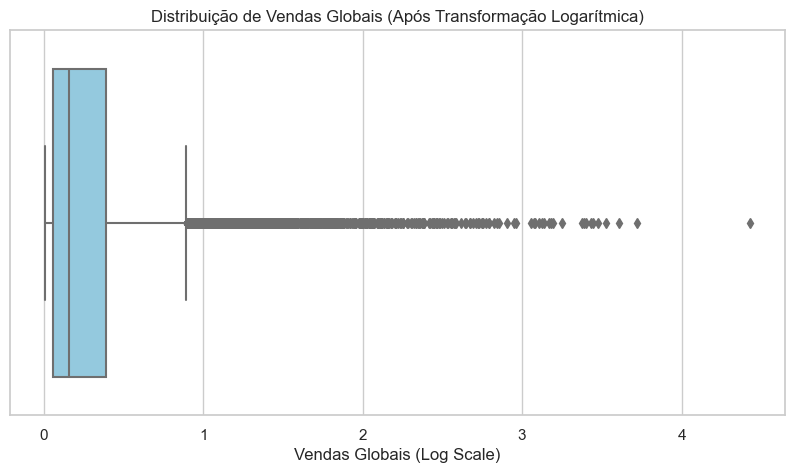

In [23]:
import numpy as np

# 1. Reduzindo a cardinalidade de 'Publisher'
top_15_publishers = df_clean['Publisher'].value_counts().index[:15]
df_clean['Publisher_Grouped'] = df_clean['Publisher'].apply(lambda x: x if x in top_15_publishers else 'Other')

print("Nova distribuição de Editoras:")
display(df_clean['Publisher_Grouped'].value_counts().head())

# 2. Transformação Logarítmica das Vendas
sales_columns = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

for col in sales_columns:
    df_clean[col + '_log'] = np.log1p(df_clean[col])

plt.figure(figsize=(10, 5))
sns.boxplot(x=df_clean['Global_Sales_log'], color='skyblue')
plt.title('Distribuição de Vendas Globais (Após Transformação Logarítmica)')
plt.xlabel('Vendas Globais (Log Scale)')
plt.show()

In [24]:

df_clean.to_csv('vgsales_cleaned.csv', index=False)

print("Dataset preparado e salvo com sucesso como 'vgsales_cleaned.csv'!")

Dataset preparado e salvo com sucesso como 'vgsales_cleaned.csv'!
